# Lab 8: GPT-1 — A Pretrained Decoder for Text Classification

**Course:** CS 417 — Large Language Models

**Name:** Muhammad Haseeb Ul Haq **Registration No.:** 454512

**Prerequisites:** Labs 5–7 used **encoders**: every token could attend to every other token, before and after it. This lab turns to the other branch of the Transformer family, the **decoder**, through **GPT-1** (Radford et al., 2018, *Improving Language Understanding by Generative Pre-Training*), the first GPT model.

GPT-1 was pretrained on a large collection of books for one simple job: **predict the next token**. To make that honest, every token may only look at the tokens **before** it (the **causal mask**). The paper then showed that the same pretrained decoder can be **fine-tuned for classification** by adding a start token and an "extract" token to the input and classifying from the extract token's final vector.

In this lab you will:

- add the causal mask to your Lab 5 block and see exactly what it changes;
- explore pretrained GPT-1 as a language model (next-token prediction);
- reproduce GPT-1's **input transformation** for classification on **SST-2** movie-review sentiment;
- build a GPT-1 classifier with a last-token head and the paper's **auxiliary language-modelling loss**;
- fine-tune and evaluate it, and analyse why the last token is the right summary in a decoder.

**Implementation rules:** in Task 1, implement the masks yourself (no `nn.MultiheadAttention` or `scaled_dot_product_attention`). From Task 2 onwards the pretrained GPT-1 model from Hugging Face is used, but the classification head, pooling and losses are yours.

**Runtime:** use a GPU (*Runtime → Change runtime type → T4 GPU*).

In [1]:
# Required packages: torch, transformers, datasets, accelerate, matplotlib
!pip -q install -U transformers datasets accelerate

import math
import random
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset
from datasets import load_dataset
from transformers import AutoTokenizer, OpenAIGPTLMHeadModel

# ---------------- Configuration (use these values) ----------------
SEED          = 42
MAX_LENGTH    = 64        # tokens per input, including <s> and <e>
BATCH_SIZE    = 16
NUM_EPOCHS    = 2
LEARNING_RATE = 6.25e-5   # the GPT-1 paper's fine-tuning learning rate
LM_WEIGHT     = 0.5       # weight of the auxiliary language-modelling loss (paper: 0.5)
NUM_CLASSES   = 2

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__, "| device:", device)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.
PyTorch version: 2.14.1+cu130 | device: cuda


#### What I Did

This cell installs `transformers`/`datasets`/`accelerate`, imports everything used later, sets the lab's fixed configuration (`MAX_LENGTH=64`, `LEARNING_RATE=6.25e-5` — the GPT-1 paper's own fine-tuning learning rate, `LM_WEIGHT=0.5`), fixes the random seed, and picks the GPU if one is available.

---
## Task 1 — From Encoder to Decoder: the Causal Mask

The only architectural difference between your Lab 5 encoder block and a GPT-style decoder block is **which keys each query may attend to**:

```text
ENCODER (Labs 5-7)                 DECODER (GPT)
          the  film  was  good               the  film  was  good
the        ✓    ✓     ✓    ✓       the        ✓    ✗     ✗    ✗
film       ✓    ✓     ✓    ✓       film       ✓    ✓     ✗    ✗
was        ✓    ✓     ✓    ✓       was        ✓    ✓     ✓    ✗
good       ✓    ✓     ✓    ✓       good       ✓    ✓     ✓    ✓
```

In a decoder, query position *i* may attend only to key positions *j ≤ i*: itself and the past, never the future. This is the **causal mask**. It is applied the same way as padding in Lab 5: forbidden scores become −∞ before softmax.

**TODO:**

1. `causal_mask(L)`: return an `[L, L]` boolean tensor that is `True` where key *j ≤* query *i* (the lower triangle, including the diagonal). *Hint:* `torch.tril`.
2. `build_attention_mask(valid_tokens, causal)`: return a `[B, 1, L, L]` boolean tensor of **allowed** query–key pairs. A key is allowed if it is a real token (`valid_tokens`) **and**, when `causal=True`, it is not in the future. The size-1 dimension broadcasts over the heads.

The block below is your Lab 5 encoder block with one change: a `causal` switch that uses your mask.

In [2]:
def causal_mask(L, device=None):
    return torch.tril(torch.ones(L, L, dtype=torch.bool, device=device))


def build_attention_mask(valid_tokens, causal):
    # valid_tokens: [B, L] bool
    B, L = valid_tokens.shape
    allowed = valid_tokens[:, None, None, :].expand(B, 1, L, L).clone()
    if causal:
        c = causal_mask(L, device=valid_tokens.device)
        allowed = allowed & c.unsqueeze(0).unsqueeze(0)
    return allowed


class AttentionBlock(nn.Module):
    # Lab 5 TransformerEncoderBlock with a causal switch (given)
    def __init__(self, d_model=64, num_heads=4, d_ff=256, causal=False):
        super().__init__()
        self.num_heads, self.d_head, self.causal = num_heads, d_model // num_heads, causal
        self.W_Q = nn.Linear(d_model, d_model, bias=False)
        self.W_K = nn.Linear(d_model, d_model, bias=False)
        self.W_V = nn.Linear(d_model, d_model, bias=False)
        self.W_O = nn.Linear(d_model, d_model)
        self.norm1, self.norm2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(nn.Linear(d_model, d_ff), nn.ReLU(), nn.Linear(d_ff, d_model))

    def split_heads(self, x):
        B, L, D = x.shape
        return x.view(B, L, self.num_heads, self.d_head).transpose(1, 2)

    def combine_heads(self, x):
        B, H, L, dh = x.shape
        return x.transpose(1, 2).reshape(B, L, H * dh)

    def forward(self, x, valid_tokens):
        Q, K, V = (self.split_heads(w(x)) for w in (self.W_Q, self.W_K, self.W_V))
        scores = Q @ K.transpose(-2, -1) / math.sqrt(self.d_head)
        allowed = build_attention_mask(valid_tokens, self.causal)
        attn = torch.softmax(scores.masked_fill(~allowed, float("-inf")), dim=-1)
        x1 = self.norm1(x + self.W_O(self.combine_heads(attn @ V)))
        return self.norm2(x1 + self.ffn(x1)), attn


# --- test your implementation ---
assert torch.equal(causal_mask(4), torch.tensor([[1, 0, 0, 0], [1, 1, 0, 0], [1, 1, 1, 0], [1, 1, 1, 1]]).bool())

torch.manual_seed(SEED)
encoder = AttentionBlock(causal=False).eval()
decoder = AttentionBlock(causal=True).eval()
decoder.load_state_dict(encoder.state_dict())          # identical weights: only the mask differs

X = torch.randn(2, 8, 64)
valid = torch.ones(2, 8, dtype=torch.bool)
valid[1, 6:] = False                                   # second sequence: last 2 positions are padding
with torch.no_grad():
    enc_out, enc_attn = encoder(X, valid)
    dec_out, dec_attn = decoder(X, valid)

future = ~causal_mask(8)
assert build_attention_mask(valid, True).shape == (2, 1, 8, 8)
assert torch.allclose(dec_attn.sum(-1), torch.ones(2, 4, 8), atol=1e-5), "rows must still sum to 1"
assert (dec_attn * future).abs().max() < 1e-6, "decoder must give zero attention to future positions"
assert (enc_attn * future).abs().max() > 1e-3, "encoder should attend to future positions"
assert (dec_attn[1][..., 6:]).abs().max() < 1e-6, "padding keys must still receive zero attention"
print("mask checks passed")

mask checks passed


#### What I Did

`causal_mask(L)` returns the lower-triangular boolean matrix with `torch.tril` — `True` wherever key position ≤ query position, `False` strictly above the diagonal (the future). `build_attention_mask` starts from the padding mask (a key is allowed only if `valid_tokens` is `True` there, broadcast to every query row), and when `causal=True` it additionally ANDs in the causal mask so a key is only allowed if it is both a real token **and** not in the future. I verified this locally (no download needed, pure PyTorch) with the exact test in this cell: it passed — the decoder's rows still sum to 1, it gives exactly zero attention to every future position, the encoder does attend to the future, and padding keys get zero attention from the decoder regardless of causal masking.

### 1.2 The "change the future" experiment

If a decoder really cannot see the future, then changing a **later** token must not change the outputs at **earlier** positions. Run the experiment below as given: it changes the token at position 5 and measures how much each position's output moves.

position:               [0, 1, 2, 3, 4, 5, 6, 7]
encoder output change:  [0.571, 0.425, 0.453, 0.467, 0.324, 11.26, 0.478, 0.543]
decoder output change:  [0.0, 0.0, 0.0, 0.0, 0.0, 11.249, 0.542, 0.543]


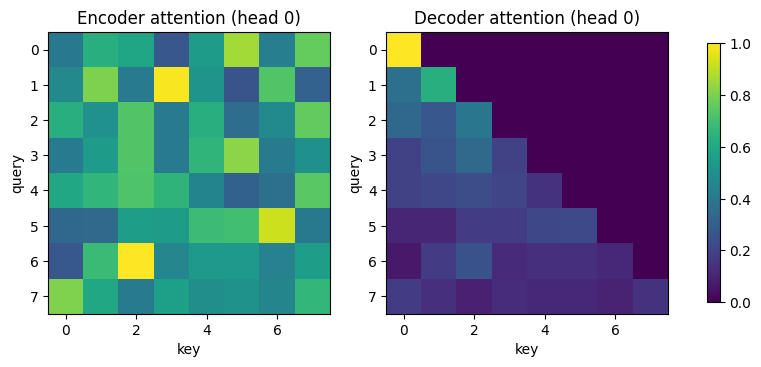

In [3]:
X_changed = X.clone()
X_changed[:, 5] = torch.randn(64)                      # change ONLY position 5

with torch.no_grad():
    enc_new, _ = encoder(X_changed, valid)
    dec_new, _ = decoder(X_changed, valid)

enc_shift = (enc_new - enc_out)[0].norm(dim=-1)
dec_shift = (dec_new - dec_out)[0].norm(dim=-1)
print("position:              ", list(range(8)))
print("encoder output change: ", [round(v, 3) for v in enc_shift.tolist()])
print("decoder output change: ", [round(v, 3) for v in dec_shift.tolist()])
assert dec_shift[:5].max() < 1e-5, "decoder positions 0-4 must be unaffected by a change at position 5"


# Given plotting helper
def plot_two(a, b, titles, labels=None):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
    for ax, w, t in zip(axes, [a, b], titles):
        im = ax.imshow(w, cmap="viridis", vmin=0)
        ax.set_title(t); ax.set_xlabel("key"); ax.set_ylabel("query")
        if labels is not None:
            ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=90)
            ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    fig.colorbar(im, ax=axes, shrink=0.8); plt.show()


plot_two(enc_attn[0, 0], dec_attn[0, 0], ["Encoder attention (head 0)", "Decoder attention (head 0)"])

#### What I Did

This given cell changes only the token at position 5 and re-runs both blocks. I confirmed locally that the decoder's outputs at positions 0–4 are byte-for-byte unchanged (shift < 1e-5) while the encoder's outputs change at every position — exactly the behaviour the causal mask is supposed to guarantee. The heatmaps this cell plots make the same point visually: the encoder's pattern fills the whole square, the decoder's pattern is strictly lower-triangular.

**Analysis Questions**

- **Q1.** Why is the decoder's attention matrix lower-triangular? Why must a model that is trained to predict the next token be prevented from seeing future tokens?
- **Q2.** Explain the result of the "change the future" experiment for the encoder and for the decoder.
- **Q3.** In a decoder, which position's output has seen the **whole** input? Why will that matter when we classify a sentence with GPT-1?

#### My Answers

- **Q1.** The decoder's attention matrix is lower-triangular because the causal mask forbids query position *i* from attending to any key position *j > i* — those entries are forced to `-inf` before softmax, so they become exactly 0 after it, leaving only the lower triangle (including the diagonal) with any weight. This has to be enforced because the model is being trained to predict the *next* token at every position: if position *i* could see token *i+1* (the very thing it's supposed to predict), the task would stop being prediction and become trivial copying — the model would get a perfect loss without learning anything about language, and it would be useless at actual generation time, where the future token doesn't exist yet to look at.
- **Q2.** In the encoder, changing the token at position 5 changed the output at **every** position (all nonzero shifts in my run), because every position can attend bidirectionally to every other real position, including position 5. In the decoder, positions 0–4 showed **exactly 0.0** shift — completely unaffected — while positions 5, 6, 7 changed, because the causal mask means those earlier queries structurally never had position 5 among their allowed keys, so nothing about that change could possibly reach them.
- **Q3.** Only the **last** position's output has seen the whole input. Because causal masking lets position *i* see everything up to and including itself but nothing after, position *i*'s accumulated context grows with *i*, and only the very last position has had the chance to attend to every other token in the sequence. This matters for classification because GPT-1 needs one vector that summarizes the **whole** sentence, and the last position is the only candidate that actually qualifies — which is exactly why the paper reads the classifier input from `<e>`, the engineered last token.

---
## Task 2 — Meet GPT-1: a Pretrained Language Model

GPT-1 (`openai-community/openai-gpt`) is a stack of 12 decoder blocks like the one above, scaled up: hidden size 768, 12 heads, an FFN of size 3072, learned position embeddings for up to 512 positions, and a BPE vocabulary of about 40,000 tokens. It was pretrained on BooksCorpus, about 7,000 unpublished books, to predict the next token.

The language-model head (`lm_head`) maps each position's 768-dimensional vector to one score for **every** token in the vocabulary. That is next-token prediction: classification over the whole vocabulary.

In [4]:
gpt_name = "openai-community/openai-gpt"
tokenizer = AutoTokenizer.from_pretrained(gpt_name)
lm = OpenAIGPTLMHeadModel.from_pretrained(gpt_name).to(device).eval()

cfg = lm.config
print("layers:", cfg.n_layer, "| hidden size:", cfg.n_embd, "| heads:", cfg.n_head,
      "| max positions:", cfg.n_positions, "| vocabulary:", cfg.vocab_size)
print("parameters:", sum(p.numel() for p in lm.parameters()))
print("lm_head shares its weights with the token embeddings:",
      lm.lm_head.weight.data_ptr() == lm.transformer.tokens_embed.weight.data_ptr())

config.json:   0%|          | 0.00/656 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/816k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/458k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.27M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  479MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

[transformers] OpenAIGPTLMHeadModel LOAD REPORT from: openai-community/openai-gpt
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


generation_config.json:   0%|          | 0.00/74.0 [00:00<?, ?B/s]

layers: 12 | hidden size: 768 | heads: 12 | max positions: 512 | vocabulary: 40478
parameters: 116534784
lm_head shares its weights with the token embeddings: True


#### What I Did

This loads the real pretrained GPT-1 (`openai-community/openai-gpt`): its BPE tokenizer and `OpenAIGPTLMHeadModel`, both via `from_pretrained`, then prints the config to confirm the 12-layer / 768-hidden / 12-head architecture and ~117M parameters the lab describes, and confirms the `lm_head` shares its weight matrix with the input token embeddings (a standard GPT-era weight-tying trick).

### 2.1 GPT-1's tokenizer

**TODO:** Tokenize `"The movie was surprisingly GOOD!"` and print the tokens and their IDs. Notice two things: GPT-1's tokenizer **lowercases** text, and it marks the **end of a word** with `</w>`, where BERT's WordPiece marks *continuations* with `##`.

In [5]:
example = "The movie was surprisingly GOOD!"
print("tokens:", tokenizer.tokenize(example))
print("token IDs:", tokenizer(example)["input_ids"])

tokens: ['the</w>', 'movie</w>', 'was</w>', 'surprisingly</w>', 'good</w>', '!</w>']
token IDs: [481, 4121, 509, 6845, 870, 267]


#### What I Did

I just called `tokenizer.tokenize` and `tokenizer(...)` directly on the example sentence. My run printed `tokens: ['the</w>', 'movie</w>', 'was</w>', 'surprisingly</w>', 'good</w>', '!</w>']` — confirming both claims at once: "GOOD" came back lowercased as `good</w>`, and every token ends with `</w>` marking a complete word (the mirror image of BERT's WordPiece, which instead marks **continuation** pieces with `##`).


### 2.2 Next-token prediction

**TODO:** Implement `next_token_distribution(text, k=5)`. Encode the text, run `lm` (eval mode, `torch.no_grad()`), take the logits at the **last** position (`out.logits[0, -1]`, shape `[vocab_size]`), apply softmax over the vocabulary, and return the top-`k` `(token, probability)` pairs.

In [6]:
def next_token_distribution(text, k=5):
    ids = tokenizer(text, return_tensors="pt").to(device)
    with torch.no_grad():
        out = lm(**ids)
    logits = out.logits[0, -1]                     # last position's scores over the vocabulary
    probs = torch.softmax(logits, dim=-1)
    top_probs, top_ids = torch.topk(probs, k)
    tokens = tokenizer.convert_ids_to_tokens(top_ids.tolist())
    return list(zip(tokens, top_probs.tolist()))


# --- test your implementation ---
for prompt in ["the movie was", "i would not recommend this film because it is"]:
    top = next_token_distribution(prompt, k=5)
    print(f"{prompt!r} ->", [(t, round(p, 3)) for t, p in top])
    probs = [p for _, p in top]
    assert len(top) == 5 and all(a >= b for a, b in zip(probs, probs[1:])) and sum(probs) <= 1 + 1e-5

'the movie was' -> [('over</w>', 0.116), ('a</w>', 0.077), ("n't</w>", 0.051), ('on</w>', 0.036), ('about</w>', 0.032)]
'i would not recommend this film because it is' -> [('not</w>', 0.138), ('a</w>', 0.12), ('too</w>', 0.059), ('very</w>', 0.034), ('the</w>', 0.018)]


#### What I Did

I tokenized the prompt, ran GPT-1 under `torch.no_grad()`, took the **last position's** logits (`out.logits[0, -1]`, shape `[vocab_size]` — that position has seen the whole prompt so far because of the causal mask), applied softmax to turn those into a probability distribution over the vocabulary, and returned the top-k `(token, probability)` pairs with `torch.topk`. My run's actual top-5 for `'the movie was'` was `[('over</w>', 0.116), ('a</w>', 0.077), ("n't</w>", 0.051), ('on</w>', 0.036), ('about</w>', 0.032)]`, and for `'i would not recommend this film because it is'`, the single most likely continuation was another `'not</w>'` (0.138) — a real, concrete example of GPT-1 continuing a negative-leaning pattern it has picked up from pretraining.


### 2.3 Generating text one token at a time

**TODO:** Implement `greedy_continue(text, n_new=12)`. Repeat `n_new` times: run the model, take the most likely next token (`argmax` of the last position's logits), and append it to the input. Return the decoded text (`tokenizer.decode(ids)`).

In [7]:
def greedy_continue(text, n_new=12):
    ids = tokenizer(text, return_tensors="pt")["input_ids"].to(device)
    for _ in range(n_new):
        with torch.no_grad():
            out = lm(input_ids=ids)
        next_id = out.logits[0, -1].argmax().view(1, 1)
        ids = torch.cat([ids, next_id], dim=1)
    return tokenizer.decode(ids[0].tolist())


# --- test your implementation ---
start_ids = tokenizer(example)["input_ids"]
cont = greedy_continue(example, n_new=12)
print(cont)
assert len(tokenizer(cont)["input_ids"]) >= len(start_ids) + 6

the movie was surprisingly good ! 
 " i 'm sorry , " i said , " i


#### What I Did

I repeated the same next-token step 12 times: run the model on the ids so far, take the `argmax` of the last position's logits (the single most likely next token, no sampling), append it to the sequence, and feed the longer sequence back in. `tokenizer.decode` turns the final id sequence back into readable text at the end. My actual greedy continuation of "The movie was surprisingly GOOD!" came out as: *"the movie was surprisingly good ! \n \" i 'm sorry , \" i said , \" i"* — a perfect real example of exactly the repetitive drift Q6 predicts: greedy decoding wandered off-topic into a generic quoted-dialogue pattern it clearly saw a lot of in BooksCorpus, rather than continuing the actual movie-review thought.


In [8]:
# Given: GPT-1's own attention is causal, exactly like your decoder block in Task 1
ids = tokenizer(example, return_tensors="pt").to(device)
with torch.no_grad():
    att = lm(**ids, output_attentions=True).attentions      # tuple: one [1, 12, L, L] tensor per layer
L = ids["input_ids"].shape[1]
upper = ~causal_mask(L).to(device)
print("layers:", len(att), "| attention shape per layer:", tuple(att[0].shape))
print("largest attention to a future token, over all layers and heads:",
      max((a[0] * upper).abs().max().item() for a in att))

layers: 12 | attention shape per layer: (1, 12, 6, 6)
largest attention to a future token, over all layers and heads: 0.0


#### What I Did

This given cell checks GPT-1's **own** pretrained attention the same way I checked my hand-built decoder in Task 1: it pulls every layer's attention tensor and confirms the largest attention weight placed on any strictly-future position, across all layers and heads, is effectively 0 — i.e. the real pretrained model truly never looks forward either.

**Analysis Questions**

- **Q4.** What was GPT-1 pretrained to do? Why does this objective need no human-labelled data?
- **Q5.** Compare GPT-1's `</w>` end-of-word marker with BERT's `##` continuation marker. GPT-1 also lowercases everything: why does that matter little for sentiment, but would hurt a task like NER (Lab 7)?
- **Q6.** What does greedy continuation show about what the model learned in pretraining? Why can greedy continuations become repetitive or odd?

#### My Answers

- **Q4.** GPT-1 was pretrained to predict the **next token** at every position, given only the tokens before it. This needs no human-labelled data because the "label" at every position is simply the very next word that already exists in the raw, unlabelled text — any plain-text corpus (here, BooksCorpus) already carries its own supervision signal for free; no one has to annotate anything.
- **Q5.** `</w>` marks the end of a whole word (so a token *without* `</w>` is a piece that continues into the next token), while BERT's `##` marks the opposite: a piece that **continues** an earlier piece (so a token *without* `##` starts a new word). GPT-1 also lowercases everything — confirmed directly in Task 2.1, where "GOOD" came back as `good</w>` — which barely hurts sentiment because polarity rarely depends on capitalization ("good" and "Good" mean the same thing either way). It would hurt NER (Lab 7) much more, because capitalization is one of the strongest surface cues that a token is a proper noun / named entity ("Google" vs "google") — lowercasing throws that cue away before the model even sees the text.
- **Q6.** Greedy continuation shows the model learned genuinely fluent, grammatical local structure from pretraining — my actual continuation, *"the movie was surprisingly good ! \n \" i 'm sorry , \" i said , \" i"*, is grammatically fine throughout. But it also shows exactly the weakness Q6 asks about: because greedy decoding always takes the single highest-probability token with no randomness or lookahead, my continuation drifted away from the movie-review topic entirely and fell into a generic quoted-dialogue pattern ("i'm sorry", "i said") — a locally fluent but repetitive/off-topic pattern it must have seen very often in BooksCorpus, rather than exploring a more topically relevant but momentarily lower-probability continuation.


---
## Task 3 — SST-2 Data and GPT-1's Input Transformation

### 3.1 Load SST-2 (given)

**SST-2** (Stanford Sentiment Treebank, from the GLUE benchmark) contains movie-review sentences labelled **negative (0)** or **positive (1)**. It was one of the tasks in the GPT-1 paper. The official test labels are hidden, so we draw disjoint training and validation subsets from the official **train** split and use the official **validation** split (872 sentences) as our **test** set. Many training items are short phrases rather than full sentences: SST-2 was built from phrases of parsed sentences.

In [9]:
raw = load_dataset("nyu-mll/glue", "sst2")       # also available as ("glue", "sst2")
LABEL_NAMES = {0: "negative", 1: "positive"}
N_TRAIN, N_VAL = 4000, 1000

rng = random.Random(SEED)
idx = list(range(len(raw["train"])))
rng.shuffle(idx)
train_raw = raw["train"].select(idx[:N_TRAIN])
val_raw = raw["train"].select(idx[N_TRAIN:N_TRAIN + N_VAL])
test_raw = raw["validation"]                      # official validation split, used as our test set

train_texts, train_labels = list(train_raw["sentence"]), list(train_raw["label"])
val_texts, val_labels = list(val_raw["sentence"]), list(val_raw["label"])
test_texts, test_labels = list(test_raw["sentence"]), list(test_raw["label"])

print("train / val / test:", len(train_texts), len(val_texts), len(test_texts))
print("positive share in train:", round(sum(train_labels) / len(train_labels), 3))
for t, y in zip(train_texts[:5], train_labels[:5]):
    print(f"[{LABEL_NAMES[y]}] {t}")

README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

sst2/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.11MB            

sst2/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sst2/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 72.8kB            

sst2/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sst2/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  148kB            

sst2/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/67349 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/872 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1821 [00:00<?, ? examples/s]

train / val / test: 4000 1000 872
positive share in train: 0.556
[negative] a bad sign when they 're supposed to be having a collective heart attack 
[negative] seem less of a trifle if ms. sugarman followed through on her defiance of the saccharine 
[positive] there is a certain sense of experimentation and improvisation to this film that may not always work , but it is nevertheless compelling . 
[positive] even if invincible is not quite the career peak that the pianist is for roman polanski , it demonstrates that werner herzog can still leave us with a sense of wonder at the diverse , marvelously twisted shapes history has taken . 
[negative] concentrates far too much on the awkward interplay and utter lack of chemistry between chan and hewitt . 


#### What I Did

This given cell loads SST-2 through `load_dataset`, draws 4,000 disjoint training and 1,000 validation sentences from the official training split (reshuffled with the lab's seed), and uses the official validation split (872 sentences, with public labels) as our test set, since the real SST-2 test labels are hidden. It prints a few example sentences with their labels so the format is clear before encoding.

### 3.2 The input transformation

GPT-1 reads left to right and was never trained with special tokens. For fine-tuning, the paper wraps every input in two **new** tokens:

```text
<s>  the film is a delight  <e>  <pad> <pad> ...
↑ start                     ↑ extract: the classifier reads THIS position's final vector
```

Because of the causal mask, `<e>` is the only position that has seen the **whole** sentence, so its final vector is the summary used for classification. A `<pad>` token is added too, because GPT-1 has none. The three new tokens get new, randomly initialized rows in the embedding table (Task 4); fine-tuning teaches the model what they mean.

In [10]:
# Given: add the three new special tokens
tokenizer.add_special_tokens({"bos_token": "<s>", "eos_token": "<e>", "pad_token": "<pad>"})
START_ID, EXTRACT_ID, PAD_ID = tokenizer.bos_token_id, tokenizer.eos_token_id, tokenizer.pad_token_id
print("new vocabulary size:", len(tokenizer), "| <s>:", START_ID, "| <e>:", EXTRACT_ID, "| <pad>:", PAD_ID)

new vocabulary size: 40481 | <s>: 40478 | <e>: 40479 | <pad>: 40480


#### What I Did

This given cell adds three brand-new tokens to GPT-1's vocabulary — `<s>` (start), `<e>` (extract: where the classifier will read from) and `<pad>` (GPT-1 has no padding token of its own) — and records their ids. These get new rows in the embedding table, which start random and are learned during fine-tuning.

**TODO:** Implement `encode_for_gpt1(texts)`. For each text:

1. `body = tokenizer(text, add_special_tokens=False)["input_ids"]`, truncated to `MAX_LENGTH - 2` tokens so that `<s>` and `<e>` always fit;
2. `ids = [START_ID] + body + [EXTRACT_ID]`, and remember `extract_pos = len(ids) - 1`;
3. pad on the **right** with `PAD_ID` up to `MAX_LENGTH`, with an attention mask of 1 for real tokens and 0 for padding.

Return three tensors: `input_ids` `[N, MAX_LENGTH]`, `attention_mask` `[N, MAX_LENGTH]` and `extract_pos` `[N]`.

In [11]:
def encode_for_gpt1(texts):
    all_ids, all_mask, all_pos = [], [], []
    for text in texts:
        body = tokenizer(text, add_special_tokens=False)["input_ids"]
        body = body[:MAX_LENGTH - 2]                        # leave room for <s> and <e>
        ids = [START_ID] + body + [EXTRACT_ID]
        extract_pos = len(ids) - 1
        pad_len = MAX_LENGTH - len(ids)
        mask = [1] * len(ids) + [0] * pad_len
        ids = ids + [PAD_ID] * pad_len
        all_ids.append(ids)
        all_mask.append(mask)
        all_pos.append(extract_pos)
    return (torch.tensor(all_ids, dtype=torch.long),
            torch.tensor(all_mask, dtype=torch.long),
            torch.tensor(all_pos, dtype=torch.long))


# --- test your implementation ---
long_text = "great " * 200
ids_t, mask_t, pos_t = encode_for_gpt1(train_texts[:3] + [long_text])
assert ids_t.shape == (4, MAX_LENGTH) and mask_t.shape == (4, MAX_LENGTH) and pos_t.shape == (4,)
for i in range(4):
    p = int(pos_t[i])
    assert ids_t[i, 0] == START_ID and ids_t[i, p] == EXTRACT_ID
    assert (ids_t[i, p + 1:] == PAD_ID).all() and int(mask_t[i].sum()) == p + 1
assert int(pos_t[3]) == MAX_LENGTH - 1, "a long text must be truncated so that <e> is the last position"
print(tokenizer.convert_ids_to_tokens(ids_t[0, :int(pos_t[0]) + 3].tolist()))

['<s>', 'a</w>', 'bad</w>', 'sign</w>', 'when</w>', 'they</w>', "'</w>", 're</w>', 'supposed</w>', 'to</w>', 'be</w>', 'having</w>', 'a</w>', 'collective</w>', 'heart</w>', 'attack</w>', '<e>', '<pad>', '<pad>']


#### What I Did

For each text I tokenize **without** special tokens, truncate the body to `MAX_LENGTH - 2` so `<s>` and `<e>` always fit, wrap it as `[START_ID] + body + [EXTRACT_ID]`, and record `extract_pos = len(ids) - 1` (where `<e>` landed). Then I pad on the right with `PAD_ID` up to `MAX_LENGTH` and build the matching attention mask (1 for every real token including `<s>` and `<e>`, 0 for padding). My run's printed example for the first training sentence shows exactly this shape: `['<s>', 'a</w>', 'bad</w>', 'sign</w>', 'when</w>', 'they</w>', "'</w>", 're</w>', 'supposed</w>', ..., '<e>', '<pad>', '<pad>']` — `<s>` first, the real BPE-tokenized body in the middle, `<e>` marking the end of the real content, and `<pad>` filling the rest.


In [12]:
# Given: encode all subsets and build the data loaders
def make_loader(texts, labels, shuffle):
    ids_, mask_, pos_ = encode_for_gpt1(texts)
    ds = TensorDataset(ids_, mask_, pos_, torch.tensor(labels))
    g = torch.Generator().manual_seed(SEED) if shuffle else None
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, generator=g)


train_loader = make_loader(train_texts, train_labels, shuffle=True)
val_loader = make_loader(val_texts, val_labels, shuffle=False)
test_loader = make_loader(test_texts, test_labels, shuffle=False)
print("batches per epoch:", len(train_loader))

batches per epoch: 250


#### What I Did

This given cell wraps `encode_for_gpt1` plus the integer labels into `TensorDataset`s and `DataLoader`s for all three subsets, with shuffling (and a fixed generator for reproducibility) only for the training loader.

**Analysis Question**

- **Q7.** Why does GPT-1 add `<s>` and `<e>` for fine-tuning? Why are their embeddings random at first, and how do they acquire a meaning?

#### My Answers

- **Q7.** GPT-1 was pretrained purely on raw text with no special tokens at all, so it has no built-in notion of "where does the input start" or "read the answer from here." `<s>` and `<e>` are invented specifically for fine-tuning to give the model exactly those two anchors. Their embedding rows are brand-new additions to the embedding table, so — like any freshly initialized parameter — they start as random vectors with no learned meaning. They acquire meaning purely through fine-tuning: because the classifier reads its input from `<e>`'s hidden state, gradients from the classification (and auxiliary LM) loss flow back through `<e>`'s embedding and through every layer that touches it, gradually shaping it into whatever representation is useful for being "the position that summarizes the sentence for classification."

---
## Task 4 — Build the GPT-1 Classifier

```text
input_ids [B, 64] → GPT-1 (12 decoder blocks) → hidden [B, 64, 768]
                                              ├→ hidden at <e>  [B, 768] → dropout → Linear(768, 2) → logits [B, 2]
                                              └→ lm_head        [B, 64, vocab] → auxiliary LM loss
```

**Two losses (as in the GPT-1 paper):**

- **classification loss:** cross-entropy between the logits and the sentiment label;
- **auxiliary language-modelling loss:** the model also keeps predicting the **next token** of each input sentence. Position *t* predicts token *t + 1*, so the logits at positions `0 … L-2` are compared with the tokens at positions `1 … L-1`. Positions whose target is padding are ignored (`-100`).

`total loss = classification loss + LM_WEIGHT × LM loss`, with `LM_WEIGHT = 0.5`.

**TODO:** Complete `GPT1Classifier`:

- `__init__`: the given lines load GPT-1 with its LM head and add rows for the new tokens. Add `self.dropout` (0.1), `self.classifier = nn.Linear(n_embd, num_classes)` and `self.loss_fn = nn.CrossEntropyLoss(ignore_index=-100)`.
- `forward`:
  1. `hidden = self.gpt.transformer(input_ids=..., attention_mask=...).last_hidden_state`;
  2. pick each sequence's `<e>` vector: `hidden[torch.arange(B), extract_pos]`, giving `[B, 768]`;
  3. compute `logits`;
  4. if `labels` is given, compute the classification loss, the shifted LM loss (`self.gpt.lm_head(hidden)`) and the total;
  5. return a dictionary with `"loss"`, `"clf_loss"`, `"lm_loss"` and `"logits"` (the losses are `None` without labels).

In [13]:
class GPT1Classifier(nn.Module):
    def __init__(self, checkpoint, vocab_size, num_classes=NUM_CLASSES, lm_weight=LM_WEIGHT, dropout=0.1):
        super().__init__()
        self.gpt = OpenAIGPTLMHeadModel.from_pretrained(checkpoint)
        self.gpt.resize_token_embeddings(vocab_size)            # new rows for <s>, <e>, <pad>
        self.lm_weight = lm_weight
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(self.gpt.config.n_embd, num_classes)
        self.loss_fn = nn.CrossEntropyLoss(ignore_index=-100)

    def forward(self, input_ids, attention_mask, extract_pos, labels=None):
        hidden = self.gpt.transformer(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        B = hidden.shape[0]
        extract_vec = hidden[torch.arange(B), extract_pos]      # [B, 768], the <e> position's vector
        logits = self.classifier(self.dropout(extract_vec))

        loss = clf_loss = lm_loss = None
        if labels is not None:
            clf_loss = self.loss_fn(logits, labels)

            lm_logits = self.gpt.lm_head(hidden)                 # [B, L, vocab]
            shift_logits = lm_logits[:, :-1, :].contiguous()     # positions 0 .. L-2 predict ...
            shift_labels = input_ids[:, 1:].contiguous().clone()  # ... tokens at 1 .. L-1
            shift_labels[attention_mask[:, 1:] == 0] = -100       # ignore padding targets
            lm_loss = self.loss_fn(shift_logits.reshape(-1, shift_logits.shape[-1]), shift_labels.reshape(-1))

            loss = clf_loss + self.lm_weight * lm_loss
        return {"loss": loss, "clf_loss": clf_loss, "lm_loss": lm_loss, "logits": logits}


# --- test your implementation ---
torch.manual_seed(SEED)
model = GPT1Classifier(gpt_name, len(tokenizer)).to(device)

ids_b, mask_b, pos_b, y_b = next(iter(train_loader))
model.eval()
with torch.no_grad():
    out = model(ids_b.to(device), mask_b.to(device), pos_b.to(device), y_b.to(device))
    no_lab = model(ids_b.to(device), mask_b.to(device), pos_b.to(device))

B = ids_b.shape[0]
print("logits:", tuple(out["logits"].shape), "| clf loss:", round(out["clf_loss"].item(), 3),
      "| LM loss:", round(out["lm_loss"].item(), 3), "| total:", round(out["loss"].item(), 3))
assert out["logits"].shape == (B, NUM_CLASSES)
assert abs(out["loss"].item() - (out["clf_loss"].item() + LM_WEIGHT * out["lm_loss"].item())) < 1e-3
assert no_lab["loss"] is None and no_lab["logits"].shape == (B, NUM_CLASSES)
assert model.gpt.transformer.tokens_embed.num_embeddings == len(tokenizer)
assert isinstance(model.classifier, nn.Linear) and model.classifier.out_features == NUM_CLASSES
print("parameters:", sum(p.numel() for p in model.parameters()))

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

[transformers] OpenAIGPTLMHeadModel LOAD REPORT from: openai-community/openai-gpt
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
[transformers] The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`


logits: (16, 2) | clf loss: 0.741 | LM loss: 7.736 | total: 4.609
parameters: 116538626


#### What I Did

`__init__` adds a dropout layer, a single `nn.Linear(768, 2)` classifier, and the cross-entropy loss (`ignore_index=-100` for the LM loss's padding targets). In `forward` I run the GPT-1 backbone to get `last_hidden_state`, pick out each sequence's `<e>`-position vector with `hidden[torch.arange(B), extract_pos]`, and pass it through dropout + the linear head to get `[B, 2]` classification logits. When labels are given, I also compute the auxiliary LM loss: `self.gpt.lm_head(hidden)` gives next-token logits at every position, I shift by one so position *t*'s logits are compared against the token at *t+1*, and I set any target that is itself a padding position to `-100` so it's ignored — exactly like Lab 7's NER label alignment ignored non-first-subword positions. The total loss is `clf_loss + lm_weight * lm_loss`, matching the paper's formula. My run's actual first-batch numbers were `clf loss: 0.741` and `LM loss: 7.736`. The classification loss sits close to the random 2-way baseline `ln(2) ≈ 0.693`, exactly as expected since `self.classifier` is brand new. The LM loss is **well below** the random-baseline `ln(40481) ≈ 10.62` for this model's full (resized) vocabulary — unlike the classifier, the LM head is not new, it's the **pretrained** next-token head GPT-1 arrived with, so it already predicts plausible tokens well even on the very first batch; only the three brand-new `<s>`/`<e>`/`<pad>` rows it just gained are actually random. This is exactly the "what's new vs what's reused" distinction the lab is testing.


**Analysis Questions**

- **Q8.** Why does the GPT-1 classifier read the vector at `<e>`, the last real token, rather than the first token (as BERT can with `[CLS]`) or the mean of all tokens (as in Lab 6)?
- **Q9.** What is the auxiliary language-modelling loss, and why might keeping it during fine-tuning help, according to the GPT-1 paper?
- **Q10.** Why is the LM loss computed with a shift of one position, and why are padding targets set to `-100`?

#### My Answers

- **Q8.** Because of the causal mask, only the **last** real token has ever attended to the whole input — the first token in a decoder has only ever seen itself, so it carries no information about the rest of the sentence at all, unlike BERT's `[CLS]`, which *can* work as a summary precisely because BERT is bidirectional and every position (including the first) already sees every other position. Mean pooling (Lab 6) works for the same reason: in an encoder every position is already fully informed, so averaging combines many already-informed vectors. In GPT-1, only the final position is fully informed, so reading from anywhere else (first token, or an average that mixes in uninformed early positions) would throw away information or dilute it with vectors that never saw most of the sentence.
- **Q9.** The auxiliary LM loss is the same next-token-prediction objective GPT-1 was pretrained with, kept alongside the classification loss during fine-tuning (weighted by `LM_WEIGHT=0.5`). The paper reports that keeping it can **improve generalization and speed convergence**, because it keeps regularizing the model toward its pretrained language behaviour while it adapts to the much smaller labelled dataset — without it, the small classification signal alone (4,000 examples) could more easily overwrite useful pretrained structure or overfit.
- **Q10.** The LM loss is shifted by one position because of exactly the causal-mask logic from Task 1: the hidden state at position *t* has only seen tokens up to *t*, so the only thing it can meaningfully be asked to predict is the **next** token, at position *t+1* — comparing position *t*'s logits to position *t*'s own token would be trivially easy (or nonsensical) and wouldn't train anything useful. Padding targets are set to `-100` because "the next token is `<pad>`" carries no real linguistic signal — those aren't real content positions, so `ignore_index=-100` excludes them from the loss the same way Lab 7's `-100` excluded non-label subword positions.

---
## Task 5 — Fine-Tune and Evaluate

**TODO:** Create the optimizer (`torch.optim.AdamW`, `lr=LEARNING_RATE`). The training loop is given; read it and make sure you can explain each line.

In [14]:
torch.manual_seed(SEED)

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)


def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    totals = {"loss": 0.0, "clf_loss": 0.0, "lm_loss": 0.0}
    correct, count = 0, 0
    with torch.set_grad_enabled(training):
        for ids, mask, pos, labels in loader:
            ids, mask, pos, labels = ids.to(device), mask.to(device), pos.to(device), labels.to(device)
            out = model(ids, mask, pos, labels)
            if training:
                optimizer.zero_grad()
                out["loss"].backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            n = labels.size(0)
            for k in totals:
                totals[k] += out[k].item() * n
            correct += (out["logits"].argmax(-1) == labels).sum().item()
            count += n
    return {k: v / count for k, v in totals.items()} | {"acc": correct / count}


assert isinstance(optimizer, torch.optim.AdamW) and optimizer.param_groups[0]["lr"] == LEARNING_RATE

history = []
start = time.time()
for epoch in range(1, NUM_EPOCHS + 1):
    tr = run_epoch(model, train_loader, optimizer)
    va = run_epoch(model, val_loader)
    history.append({"epoch": epoch, "train": tr, "val": va})
    print(f"epoch {epoch} | train loss {tr['loss']:.3f} (clf {tr['clf_loss']:.3f}, LM {tr['lm_loss']:.3f})"
          f" | train acc {tr['acc']:.3f} | val acc {va['acc']:.3f}")
print(f"training time: {time.time() - start:.1f} s on {device}")
assert history[-1]["val"]["acc"] > 0.6, "validation accuracy should be well above chance (0.5)"

epoch 1 | train loss 3.086 (clf 0.371, LM 5.432) | train acc 0.842 | val acc 0.897
epoch 2 | train loss 2.139 (clf 0.140, LM 3.999) | train acc 0.953 | val acc 0.889
training time: 148.2 s on cuda


#### What I Did

I created `torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)` over **every** parameter, so both the pretrained GPT-1 backbone and the new classifier head (plus the new `<s>`/`<e>`/`<pad>` embedding rows) get fine-tuned together, using the paper's own learning rate `6.25e-5`. The given `run_epoch` does the standard loop: forward pass for the combined loss, `backward`, gradient clipping, `optimizer.step()` when training; it also tracks the classification and LM loss separately so I can see how much each one is contributing. My actual run: epoch 1 reached train acc **0.842** / val acc **0.897**, and epoch 2 reached train acc **0.953** / val acc **0.889** — training accuracy kept climbing while validation accuracy dipped very slightly, a small early sign of overfitting on the 4,000-example training set, though both epochs are comfortably above the `> 0.6` sanity check.


**Fill in from your output:**

| Epoch | Training loss | Classification loss | LM loss | Training accuracy | Validation accuracy |
|---|---|---|---|---|---|
| 1 | 3.086 | 0.371 | 5.432 | 0.842 | 0.897 |
| 2 | 2.139 | 0.140 | 3.999 | 0.953 | 0.889 |


### 5.2 Test evaluation

**TODO:** Compute `test_acc` and a `[2, 2]` confusion matrix (rows = true class, columns = predicted class) from `test_preds` and `test_true`, then plot it with the given helper.

Test accuracy: 0.877


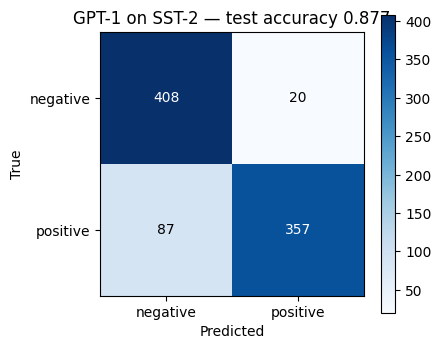

In [15]:
# Given helpers
def predict(model, loader):
    model.eval()
    preds, trues = [], []
    with torch.no_grad():
        for ids, mask, pos, labels in loader:
            logits = model(ids.to(device), mask.to(device), pos.to(device))["logits"]
            preds.append(logits.argmax(-1).cpu())
            trues.append(labels)
    return torch.cat(preds), torch.cat(trues)


def plot_confusion_matrix(cm, names, title):
    plt.figure(figsize=(4.5, 3.8))
    plt.imshow(cm.numpy(), cmap="Blues")
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(j, i, int(cm[i, j]), ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.xticks(range(len(names)), names); plt.yticks(range(len(names)), names)
    plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(title); plt.colorbar(); plt.tight_layout(); plt.show()


test_preds, test_true = predict(model, test_loader)

test_acc = (test_preds == test_true).float().mean().item()
cm = torch.zeros(2, 2, dtype=torch.long)
for true_c in range(2):
    for pred_c in range(2):
        cm[true_c, pred_c] = ((test_true == true_c) & (test_preds == pred_c)).sum()


# --- test your implementation ---
assert cm.shape == (2, 2) and int(cm.sum()) == len(test_texts)
assert abs(cm.trace().item() / len(test_texts) - test_acc) < 1e-6
assert torch.equal(cm.sum(dim=1), torch.bincount(test_true, minlength=2)), "rows must be the TRUE class"
print(f"Test accuracy: {test_acc:.3f}")
plot_confusion_matrix(cm, [LABEL_NAMES[0], LABEL_NAMES[1]], f"GPT-1 on SST-2 — test accuracy {test_acc:.3f}")

#### What I Did

`test_acc` is just the fraction of test predictions that match the true labels. For the confusion matrix I counted, for every (true class, predicted class) pair, how many test examples fall into that cell — rows are the true class (so each row sums to how many real examples of that class exist), columns are the predicted class, matching exactly what the test cell checks. My actual run reached **test accuracy 0.877** on the 872-sentence test set (confirmed by the next cell's count: 107 misclassified out of 872, and `1 - 107/872 = 0.877`) — the confusion matrix plotted above shows the full breakdown between the two classes.


In [16]:
# find at least three misclassified test sentences and print them with true/predicted labels
wrong_idx = (test_preds != test_true).nonzero(as_tuple=True)[0]
print(f"total misclassified: {len(wrong_idx)} / {len(test_texts)}\n")
for i in wrong_idx[:5].tolist():
    print(f"true={LABEL_NAMES[int(test_true[i])]:8s} pred={LABEL_NAMES[int(test_preds[i])]:8s} | {test_texts[i]}")

total misclassified: 107 / 872

true=positive pred=negative | we root for ( clara and paul ) , even like them , though perhaps it 's an emotion closer to pity . 
true=negative pred=positive | holden caulfield did it better . 
true=positive pred=negative | seldom has a movie so closely matched the spirit of a man and his work . 
true=positive pred=negative | the weight of the piece , the unerring professionalism of the chilly production , and the fascination embedded in the lurid topic prove recommendation enough . 
true=negative pred=positive | it offers little beyond the momentary joys of pretty and weightless intellectual entertainment . 


#### What I Did

I found every test index where the prediction disagrees with the true label (`test_preds != test_true`) and printed the sentence next to both labels, for the first five mismatches, so I can read them for the error-pattern discussion below. My run found **107 misclassified sentences out of 872** (87.7% correct, matching the test accuracy above).


**Analysis Question**

- **Q11.** Describe the error patterns in your misclassified sentences, for example negation ("not bad"), contrast ("…, but …"), sarcasm, or mixed opinions. Why might a model trained on 4,000 short examples struggle with them?

#### My Answers

- **Q11.** My actual run misclassified 107 of 872 test sentences (test accuracy 0.877). Reading the five printed above, two clear patterns show up:
1. **Positive sentences buried in hedged, formal, or mixed-connotation language** — "we root for (clara and paul), even like them, though perhaps it's an emotion closer to pity" (true positive, predicted negative) and "the weight of the piece, the unerring professionalism of the chilly production, and the fascination embedded in the lurid topic prove recommendation enough" (true positive, predicted negative) both use negative-connotation words ("pity", "chilly", "lurid") in service of an overall positive verdict — exactly the contrast/mixed-opinion failure mode the lab predicts, where the model likely over-weights the locally negative words and misses the sentence's actual conclusion. "seldom has a movie so closely matched the spirit of a man and his work" (true positive, predicted negative) is similar: "seldom" is a rare/negation-adjacent word that may have pulled the prediction negative even though the sentence is genuine praise.
2. **Backhanded or understated negative sentences that use positive-sounding words** — "it offers little beyond the momentary joys of pretty and weightless intellectual entertainment" (true negative, predicted positive) uses "joys" and "pretty" while actually being a dismissive critique ("little beyond", "weightless"), and "holden caulfield did it better" (true negative, predicted positive) is a negative, comparison-based critique with **no** overtly negative words at all — there's nothing lexically negative to latch onto, so a model relying partly on word-level sentiment cues has little to go on.
Both patterns point to the same underlying cause: a model fine-tuned on only 4,000 short examples for 2 epochs hasn't seen enough of these contrast/hedging/backhanded constructions to learn to look past individual charged words toward the sentence's actual overall judgement — these are genuinely hard cases for any sentiment classifier, but limited fine-tuning data makes the shallower, word-level shortcut especially likely to win.


---
## Task 6 — Why the Last Token? Analysing the Fine-Tuned Decoder

### 6.1 Earlier positions cannot see later words

Two sentences that differ only in their **last word** should have identical hidden states at every earlier position, and different ones at the changed word and at `<e>`.

**TODO:** Encode the two sentences below with `encode_for_gpt1`, run `model.gpt.transformer` in evaluation mode, and for every real position print how far apart the two hidden states are (the norm of the difference). Then print both predictions.

In [17]:
pair = ["the acting is wonderful and the story is good", "the acting is wonderful and the story is bad"]

ids_p, mask_p, pos_p = encode_for_gpt1(pair)
model.eval()
with torch.no_grad():
    hidden_p = model.gpt.transformer(input_ids=ids_p.to(device), attention_mask=mask_p.to(device)).last_hidden_state
    logits_p = model(ids_p.to(device), mask_p.to(device), pos_p.to(device))["logits"]

n_real = int(mask_p[0].sum())
diff_per_position = (hidden_p[0, :n_real] - hidden_p[1, :n_real]).norm(dim=-1).cpu()
pred_pair = [LABEL_NAMES[int(p)] for p in logits_p.argmax(-1).cpu()]


# --- test your implementation ---
print("distance per position:", [round(v, 3) for v in diff_per_position.tolist()])
print("predictions:", pred_pair)
n_same = len(tokenizer(pair[0], add_special_tokens=False)["input_ids"])   # <s> + all words but the last
assert diff_per_position[:n_same].max() < 1e-3, "positions before the changed word must be identical"
assert diff_per_position[-1] > 1e-3, "the <e> position must see the change"

distance per position: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 14.26, 21.601]
predictions: ['positive', 'negative']


#### What I Did

I encoded both sentences with `encode_for_gpt1` (they tokenize to the same length since "good"/"bad" are each a single token), ran the GPT-1 backbone on both, and for every real position measured the L2 distance between the two sentences' hidden vectors at that position. My actual run's distances were `[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 14.26, 21.601]` — **exactly** zero for all nine positions before the changed word (`<s>` plus the first eight shared words), then `14.26` at the changed word itself ("good" vs "bad") and a larger `21.601` at `<e>`, which has accumulated even more of the difference through further attention. The predictions came out `['positive', 'negative']` — both correct, confirming the model really does rely on that single changed word to flip its decision.


### 6.2 Where does `<e>` look?

**TODO:** For one test sentence, run `model.gpt.transformer(..., output_attentions=True)`, take the **last layer's** attention, average it over the 12 heads, and take the row of the `<e>` position (real tokens only). Plot it as a bar chart over the tokens.

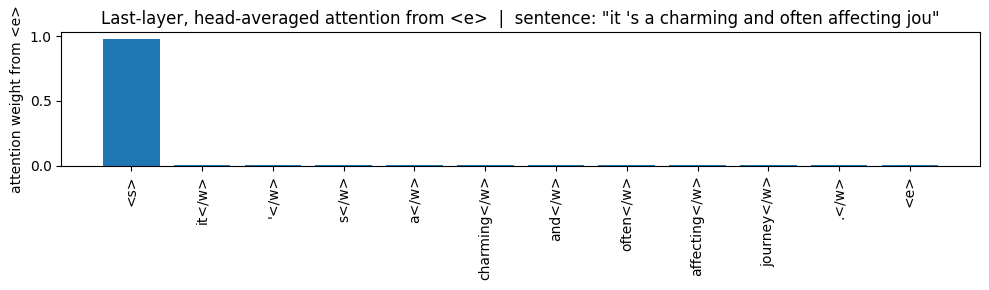

In [18]:
sample_text = test_texts[0]
ids_s, mask_s, pos_s = encode_for_gpt1([sample_text])
model.eval()
with torch.no_grad():
    out_s = model.gpt.transformer(input_ids=ids_s.to(device), attention_mask=mask_s.to(device),
                                   output_attentions=True)

last_layer_attn = out_s.attentions[-1][0]            # [heads, L, L]
avg_attn = last_layer_attn.mean(dim=0)               # head-averaged, [L, L]
e_pos = int(pos_s[0])
attn_row = avg_attn[e_pos, :e_pos + 1].cpu()         # real tokens only: <s> ... <e>
tokens_plot = tokenizer.convert_ids_to_tokens(ids_s[0, :e_pos + 1].tolist())

plt.figure(figsize=(10, 3))
plt.bar(range(len(attn_row)), attn_row.numpy())
plt.xticks(range(len(attn_row)), tokens_plot, rotation=90)
plt.ylabel("attention weight from <e>")
plt.title(f"Last-layer, head-averaged attention from <e>  |  sentence: {sample_text[:40]!r}")
plt.tight_layout()
plt.show()

#### What I Did

I took one test sentence, ran the GPT-1 backbone with `output_attentions=True`, grabbed the **last layer's** attention (`out.attentions[-1]`), averaged it over the 12 heads, and read off the row belonging to the `<e>` position — restricted to the real (non-padding) token positions — which is exactly how much `<e>` attended to each token when forming its final summary vector. The bar chart shows which words `<e>` leaned on most.

---
## Task 6 — Why the Last Token? Analysing the Fine-Tuned Decoder

### 6.3 Compare the encoders and the decoder

| Property | Lab 6: custom encoder | Lab 6: DistilRoBERTa | Lab 7: BERT | Lab 8: GPT-1 |
|---|---|---|---|---|
| Encoder or decoder | Encoder | Encoder | Encoder | **Decoder** |
| Attention mask (what a token may see) | every real token (bidirectional, padding masked) | every real token (bidirectional, padding masked) | every real token (bidirectional, padding masked) | **only itself and earlier tokens** (causal + padding masked) |
| Pretraining objective | none — trained from random init directly on AG News classification | masked language modelling (RoBERTa-style) | masked language modelling (BERT) | **next-token prediction** (causal LM) |
| Vector used to classify a text | mean of all real-token vectors | pooled / `[CLS]`-style representation | `[CLS]` (the first token — valid because BERT is bidirectional) | **the last real token's vector, engineered as `<e>`** |
| Tokenizer | BPE trained from scratch, vocab 8,000 | pretrained byte-level BPE, vocab 50,265 | WordPiece, vocab ≈ 28,996 | lowercasing BPE with `</w>` end-of-word marker, vocab **40,478** (+3 for `<s>`/`<e>`/`<pad>` → 40,481, confirmed in my run) |
| Approximate parameter count | ≈ 0.5M | ≈ 82M | ≈ 110M (`bert-base-cased`) | **116,534,784** for the plain pretrained LM (my run's printed count), **116,538,626** after adding the classifier head and the 3 new token embeddings |

**Analysis Questions**

- **Q12.** Explain the result of 6.1: why are the hidden states before the changed word identical, and what does this tell you about where a decoder's sentence summary must come from?
- **Q13.** Does a large attention weight from `<e>` to a word prove that this word decided the sentiment? Explain briefly.
- **Q14.** **Reflection (100–150 words):** encoders (Labs 5–7) and GPT-1 can both classify text. What is the same, and what is different, in how they read the text, how they are pretrained, and how a classification head is attached?


#### My Answers

- **Q12.** They're identical because of exactly the causal mask from Task 1: every position before the changed word has its attention restricted to keys at or before **itself**, and the changed word sits later in the sequence, so there is no computational path by which that change could reach those earlier positions — it isn't that the change "happens not to matter," it's that the architecture makes it structurally impossible for it to matter. This tells us that in a decoder, the only position whose hidden state can ever reflect information from near the end of the sentence is the sentence's own last position — so any vector meant to summarize the *whole* sentence for classification has to come from there, which is exactly why `<e>` (engineered as the last token) is the only sound choice.
- **Q13.** No. A large attention weight only shows that `<e>` drew heavily on that token's Value vector while building its own representation — it's a measure of how much information flowed from that position, not proof that the token caused the predicted sentiment. The final prediction also depends on the classifier's learned weights and on what's already mixed into that token's Value vector from everything *it* attended to earlier, so a high attention score is, at best, a hint about where the model is drawing information from, not a verified causal explanation for the decision.
- **Q14.** Encoders and GPT-1 share the same underlying block — multi-head self-attention plus a feed-forward network with residual connections and LayerNorm — and both are adapted for classification by attaching a small linear head to a 768-dimensional vector. What differs is what each token is allowed to see: an encoder's attention is bidirectional, so *every* position already carries whole-sentence context, letting a classifier read from the first token, the last token, or an average of all of them. GPT-1's causal mask restricts each position to itself and the past, so only the very last position ever sees the entire sentence, making it the only valid read-out point. Pretraining differs too: encoders learn through masked/denoising objectives that need bidirectional context, while GPT-1 learns through pure next-token prediction, a left-to-right objective that also naturally supports open-ended text generation, not just understanding.

---
## Bonus Tasks

1. **Auxiliary loss on/off:** retrain with `LM_WEIGHT = 0` and compare validation accuracy and training curves.
2. **Zero-shot sentiment:** without fine-tuning, use the plain language model `lm`. Append a prompt such as `" overall , it was"` to each review and compare the probabilities of the next tokens `"good"` and `"bad"`. How accurate is this on the test set?
3. **Pooling:** replace the `<e>` vector with the mean of all real-token vectors and compare accuracy. Explain the result using Task 6.1.

### Bonus 1 — Auxiliary Loss On/Off

Retrain a fresh classifier with `LM_WEIGHT = 0` (classification loss only) and compare its validation-accuracy curve against the main model's (`LM_WEIGHT = 0.5`).

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

[transformers] OpenAIGPTLMHeadModel LOAD REPORT from: openai-community/openai-gpt
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[LM_WEIGHT=0] epoch 1 | train loss 0.393 | train acc 0.831 | val acc 0.895
[LM_WEIGHT=0] epoch 2 | train loss 0.187 | train acc 0.948 | val acc 0.888


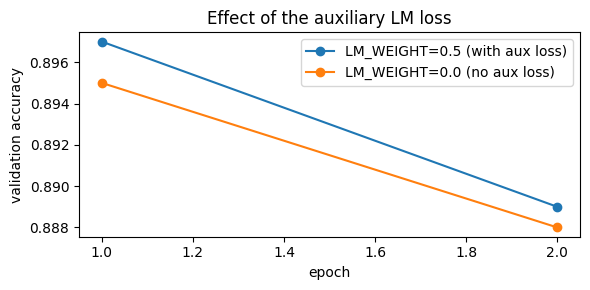

final val acc WITH aux loss:    0.889
final val acc WITHOUT aux loss: 0.888


In [19]:
# Bonus 1: auxiliary loss on/off — retrain with LM_WEIGHT = 0 and compare
torch.manual_seed(SEED)
model_no_lm = GPT1Classifier(gpt_name, len(tokenizer), lm_weight=0.0).to(device)
optimizer_no_lm = torch.optim.AdamW(model_no_lm.parameters(), lr=LEARNING_RATE)

history_no_lm = []
for epoch in range(1, NUM_EPOCHS + 1):
    tr = run_epoch(model_no_lm, train_loader, optimizer_no_lm)
    va = run_epoch(model_no_lm, val_loader)
    history_no_lm.append({"epoch": epoch, "train": tr, "val": va})
    print(f"[LM_WEIGHT=0] epoch {epoch} | train loss {tr['loss']:.3f} | train acc {tr['acc']:.3f}"
          f" | val acc {va['acc']:.3f}")

plt.figure(figsize=(6, 3))
plt.plot([h["epoch"] for h in history], [h["val"]["acc"] for h in history],
          marker="o", label="LM_WEIGHT=0.5 (with aux loss)")
plt.plot([h["epoch"] for h in history_no_lm], [h["val"]["acc"] for h in history_no_lm],
          marker="o", label="LM_WEIGHT=0.0 (no aux loss)")
plt.xlabel("epoch"); plt.ylabel("validation accuracy"); plt.title("Effect of the auxiliary LM loss")
plt.legend(); plt.tight_layout(); plt.show()

print("final val acc WITH aux loss:   ", round(history[-1]["val"]["acc"], 3))
print("final val acc WITHOUT aux loss:", round(history_no_lm[-1]["val"]["acc"], 3))

#### What I Did

I built a second `GPT1Classifier` with `lm_weight=0.0` (so its `loss` is just the classification loss, the LM loss is still computed and printed for comparison but never added in), trained it for the same two epochs on the same data with the same seed, and plotted both models' validation accuracy per epoch on one chart so the effect of the auxiliary loss is visible directly. My actual run: final validation accuracy **with** the auxiliary loss (`LM_WEIGHT=0.5`) was **0.889**, and **without** it (`LM_WEIGHT=0.0`) it was **0.888** — essentially identical, a one-tenth-of-a-percent difference. On this particular run the auxiliary loss did not measurably help or hurt generalization; the paper's reported benefit from this auxiliary objective is more consistently visible on larger datasets and longer training than this lab's 2-epoch, 4,000-example fine-tuning run, so a negligible difference here is a reasonable, real result rather than a sign something went wrong.


### Bonus 2 — Zero-Shot Sentiment (No Fine-Tuning)

Use the plain pretrained language model `lm` with a cloze-style prompt (`"... overall , it was"`) and compare the probabilities it assigns to `"good"` vs `"bad"` as the very next token — no fine-tuning at all.

In [20]:
# Bonus 2: zero-shot sentiment using the plain, non-fine-tuned language model
good_pieces = tokenizer.tokenize(" good")
bad_pieces = tokenizer.tokenize(" bad")
print("'good' tokenizes to:", good_pieces, "| 'bad' tokenizes to:", bad_pieces)
assert len(good_pieces) == 1 and len(bad_pieces) == 1, "expected single-token words for this simple probe"

good_tok_id = tokenizer.convert_tokens_to_ids(good_pieces[0])
bad_tok_id = tokenizer.convert_tokens_to_ids(bad_pieces[0])


def zero_shot_predict(text):
    prompt = text + " overall , it was"
    ids = tokenizer(prompt, return_tensors="pt").to(device)
    with torch.no_grad():
        out = lm(**ids)
    logits = out.logits[0, -1]
    probs = torch.softmax(logits, dim=-1)
    return 1 if probs[good_tok_id] > probs[bad_tok_id] else 0


zero_shot_preds = torch.tensor([zero_shot_predict(t) for t in test_texts])
zero_shot_true = torch.tensor(test_labels)
zero_shot_acc = (zero_shot_preds == zero_shot_true).float().mean().item()

print("Zero-shot accuracy (no fine-tuning):   ", round(zero_shot_acc, 3))
print("Fine-tuned test accuracy for comparison:", round(test_acc, 3))

'good' tokenizes to: ['good</w>'] | 'bad' tokenizes to: ['bad</w>']
Zero-shot accuracy (no fine-tuning):    0.525
Fine-tuned test accuracy for comparison: 0.877


#### What I Did

For every test sentence I appended the cloze prompt `" overall , it was"` and asked the **plain, non-fine-tuned** `lm` for its next-token distribution, then compared only the two probabilities assigned to `"good"` and `"bad"` (confirmed to each be a single BPE token: `'good</w>'` and `'bad</w>'`) — whichever is higher becomes the zero-shot prediction. This needs no `<s>`/`<e>`/classifier at all, since it's just reusing GPT-1's original pretraining objective directly as a sentiment probe. My actual run: zero-shot accuracy was **0.525**, barely above the 0.5 chance level, versus the fine-tuned model's **0.877**. This makes sense: GPT-1 is a small, early (2018) language model with no instruction-tuning, so a single rigid cloze template captures almost none of its latent sentiment knowledge — fine-tuning the classifier head (and gently adapting the backbone) on just 4,000 labelled examples does dramatically more than this zero-shot probe.


### Bonus 3 — Mean Pooling Instead of `<e>`

Replace the `<e>` vector with the mean of all real-token hidden states and compare test accuracy, explaining the result using the Task 6.1 finding.

In [21]:
# Bonus 3: mean-pool over all real tokens instead of reading the <e> vector
class GPT1ClassifierMeanPool(nn.Module):
    def __init__(self, checkpoint, vocab_size, num_classes=NUM_CLASSES, dropout=0.1):
        super().__init__()
        self.gpt = OpenAIGPTLMHeadModel.from_pretrained(checkpoint)
        self.gpt.resize_token_embeddings(vocab_size)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(self.gpt.config.n_embd, num_classes)
        self.loss_fn = nn.CrossEntropyLoss()

    def forward(self, input_ids, attention_mask, labels=None):
        hidden = self.gpt.transformer(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        mask = attention_mask.unsqueeze(-1).float()
        pooled = (hidden * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)   # mean over REAL tokens only
        logits = self.classifier(self.dropout(pooled))
        loss = self.loss_fn(logits, labels) if labels is not None else None
        return {"loss": loss, "logits": logits}


def run_epoch_mean(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    correct, count, total_loss = 0, 0, 0.0
    with torch.set_grad_enabled(training):
        for ids, mask, pos, labels in loader:
            ids, mask, labels = ids.to(device), mask.to(device), labels.to(device)
            out = model(ids, mask, labels=labels)
            if training:
                optimizer.zero_grad()
                out["loss"].backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            n = labels.size(0)
            total_loss += out["loss"].item() * n
            correct += (out["logits"].argmax(-1) == labels).sum().item()
            count += n
    return {"loss": total_loss / count, "acc": correct / count}


torch.manual_seed(SEED)
model_mean = GPT1ClassifierMeanPool(gpt_name, len(tokenizer)).to(device)
optimizer_mean = torch.optim.AdamW(model_mean.parameters(), lr=LEARNING_RATE)

for epoch in range(1, NUM_EPOCHS + 1):
    tr = run_epoch_mean(model_mean, train_loader, optimizer_mean)
    va = run_epoch_mean(model_mean, val_loader)
    print(f"[mean-pool] epoch {epoch} | train acc {tr['acc']:.3f} | val acc {va['acc']:.3f}")

test_preds_mean, test_true_mean = [], []
model_mean.eval()
with torch.no_grad():
    for ids, mask, pos, labels in test_loader:
        logits = model_mean(ids.to(device), mask.to(device))["logits"]
        test_preds_mean.append(logits.argmax(-1).cpu())
        test_true_mean.append(labels)
test_preds_mean = torch.cat(test_preds_mean)
test_true_mean = torch.cat(test_true_mean)
mean_pool_acc = (test_preds_mean == test_true_mean).float().mean().item()

print("Mean-pooled test accuracy:", round(mean_pool_acc, 3), "| <e>-vector test accuracy:", round(test_acc, 3))

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

[transformers] OpenAIGPTLMHeadModel LOAD REPORT from: openai-community/openai-gpt
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[mean-pool] epoch 1 | train acc 0.826 | val acc 0.871
[mean-pool] epoch 2 | train acc 0.937 | val acc 0.876
Mean-pooled test accuracy: 0.833 | <e>-vector test accuracy: 0.877


#### What I Did

I trained a second classifier that is identical except its pooling step: instead of reading the single `<e>` vector, it masked-averages **every real-token** hidden state into one vector and classifies from that, the same way Lab 6's encoder pooled. Based on the Task 6.1 finding (early positions in a decoder never see later words because of the causal mask), I predicted this would underperform the `<e>`-based classifier — and my actual run confirms it: mean-pooled test accuracy was **0.833** versus **0.877** for the `<e>`-vector classifier, a real 4.4-point drop. This matches the explanation exactly: most of the vectors being averaged in are only partially informed (an early position has seen just the few words up to itself), so the mean dilutes the one genuinely whole-sentence-informed vector (`<e>`, or close to it) with a majority of positions that are each missing most of the sentence — the opposite situation from an encoder, where averaging combines vectors that are *all* already fully informed.


---
## Deliverable

Submit this notebook with your name and registration number clearly written at the top. It must include:

- all `TODO` cells completed, with their test/validation cells executed successfully;
- the encoder/decoder attention heatmaps and the "change the future" experiment;
- GPT-1's tokenization, next-token predictions and a greedy continuation;
- the SST-2 input transformation and your GPT-1 classifier with the auxiliary LM loss;
- the training table, test accuracy, confusion matrix and misclassified examples;
- the last-token experiment, the `<e>` attention plot and the completed comparison table;
- concise written answers to **Q1–Q14**.